# Virtual Morning Exercise Coach

Демонстрационный notebook проекта виртуального коуча. Код проекта импортируется из `src/`; notebook предназначен для экспериментов, визуализации и подготовки материалов для защиты.

Основной запуск: `py -3.11 scripts/main.py`.

Структура:
```text
morning_exercise_coach/
├── src/
├── data/original/
├── data/reference/
├── examples/morning_coach_example.ipynb
├── scripts/main.py
└── output/
```


## 1. Импорты и подключение исходного кода


In [4]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "examples":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Video, display

from MyProject.config import (
    ORIGINAL_DIR, REFERENCE_DIR, PROCESSED_DIR, POSE_MODEL_PATH,
    OUTPUT_VIDEO, METRICS_CSV, PLOT_PATH, DISPLAY_WIDTH, DISPLAY_HEIGHT,
)
from MyProject.utils import find_video
from MyProject.visualization import draw_pose, metric_color
from myproject_data.preprocessing import resample_array
from myproject_models.pose_estimator import PoseEstimator
from myproject_models.pose_normalizer import normalize_pose
from myproject_models.pose_metrics import (
    cosine_similarity, weighted_distance, similarity_to_percent,
)
from myproject_models.virtual_coach import get_coach_message


## 2. Проверка окружения


In [5]:
print("Python:", sys.version)
print("Python executable:", sys.executable)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("\nКорень проекта:", PROJECT_ROOT)
print("Папка видео пользователя:", ORIGINAL_DIR)
print("Папка эталонного видео:", REFERENCE_DIR)
print("Папка результатов:", PROJECT_ROOT / "output")


Python: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
Python executable: c:\Users\aleks\AppData\Local\Programs\Python\Python311\python.exe
NumPy: 1.26.4
OpenCV: 4.10.0
MediaPipe: 0.10.14

Корень проекта: C:\Users\aleks\Documents\IDE\morning_exercise_coach
Папка видео пользователя: C:\Users\aleks\Documents\IDE\morning_exercise_coach\data\original
Папка эталонного видео: C:\Users\aleks\Documents\IDE\morning_exercise_coach\data\reference
Папка результатов: C:\Users\aleks\Documents\IDE\morning_exercise_coach\output


## 3. Поиск входных видео


In [6]:
USER_VIDEO = find_video(ORIGINAL_DIR)
REFERENCE_VIDEO = find_video(REFERENCE_DIR)

print("Видео пользователя:", USER_VIDEO)
print("Эталонное видео:", REFERENCE_VIDEO)


Видео пользователя: C:\Users\aleks\Documents\IDE\morning_exercise_coach\data\original\VID_20261009_122636.mp4
Эталонное видео: C:\Users\aleks\Documents\IDE\morning_exercise_coach\data\reference\VID_20261009_115644.mp4


## 4. Извлечение поз


In [8]:
estimator = PoseEstimator(POSE_MODEL_PATH)
reference = estimator.extract(REFERENCE_VIDEO)
user = estimator.extract(USER_VIDEO)

print("Массив поз эталонного видео:", reference.poses.shape)
print("Массив поз пользователя:", user.poses.shape)
print("FPS эталонного видео:", reference.fps)
print("FPS пользовательского видео:", user.fps)


Pose: VID_20261009_115644.mp4:   0%|          | 0/924 [00:00<?, ?it/s]c:\Users\aleks\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '
Pose: VID_20261009_122636.mp4: 100%|██████████| 382/382 [00:20<00:00, 18.85it/s]


Массив поз эталонного видео: (924, 33, 2)
Массив поз пользователя: (382, 33, 2)
FPS эталонного видео: 42.174769689546835
FPS пользовательского видео: 29.958330210858545


## 5. Сохранение ключевых точек


In [9]:
np.save(PROCESSED_DIR / "reference_poses.npy", reference.poses)
np.save(PROCESSED_DIR / "user_poses.npy", user.poses)
np.save(PROCESSED_DIR / "reference_conf.npy", reference.confidence)
np.save(PROCESSED_DIR / "user_conf.npy", user.confidence)
print("Ключевые точки сохранены в:", PROCESSED_DIR)


Ключевые точки сохранены в: C:\Users\aleks\Documents\IDE\morning_exercise_coach\data\processed


## 6. Синхронизация кадров


In [ ]:
from myproject_data.temporal_alignment import (
    align_by_normalized_time,
)


(
    reference_frame_ids,
    user_frame_ids,
    reference_poses,
    user_poses,
    reference_confidence,
    user_confidence,
) = align_by_normalized_time(
    reference.poses,
    user.poses,
    reference.confidence,
    user.confidence,
)

n_frames = len(reference_frame_ids)

print("Количество кадров эталона:", len(reference.poses))
print("Количество кадров пользователя:", len(user.poses))
print("Количество сопоставляемых пар:", n_frames)

print(
    "\nКоэффициент скорости пользователя относительно эталона:",
    round(
        len(reference.poses) / len(user.poses),
        2,
    ),
)


Количество кадров для сравнения: 382


## 7. Расчёт метрик


In [ ]:
records = []

for alignment_id in range(n_frames):
    reference_pose = normalize_pose(
        reference_poses[alignment_id]
    )

    user_pose = normalize_pose(
        user_poses[alignment_id]
    )

    if reference_pose is None or user_pose is None:
        records.append(
            {
                "alignment_id": alignment_id,
                "reference_frame": int(
                    reference_frame_ids[alignment_id]
                ),
                "user_frame": int(
                    user_frame_ids[alignment_id]
                ),
                "cosine_similarity": np.nan,
                "weighted_distance": np.nan,
                "confidence": 0.0,
            }
        )

        continue

    confidence = np.minimum(
        reference_confidence[alignment_id],
        user_confidence[alignment_id],
    )

    cosine_value = cosine_similarity(
        reference_pose,
        user_pose,
    )

    distance_value = weighted_distance(
        reference_pose,
        user_pose,
        confidence,
    )

    records.append(
        {
            "alignment_id": alignment_id,
            "reference_frame": int(
                reference_frame_ids[alignment_id]
            ),
            "user_frame": int(
                user_frame_ids[alignment_id]
            ),
            "cosine_similarity": cosine_value,
            "weighted_distance": distance_value,
            "confidence": float(
                confidence.mean()
            ),
        }
    )

metrics = pd.DataFrame(records)

metrics["similarity_percent"] = (
    metrics["cosine_similarity"]
    .apply(similarity_to_percent)
)

metrics.to_csv(
    METRICS_CSV,
    index=False,
)

,frame,cosine_similarity,weighted_distance,confidence,similarity_percent
0,0,0.928006,2.198355,0.941479,96.400294
1,1,0.928599,2.183987,0.942508,96.429956
2,2,0.927607,2.179909,0.943871,96.380350
3,3,0.927925,2.175249,0.944926,96.396229
4,4,0.927808,2.169966,0.946260,96.390393


,Среднее значение
similarity_percent,89.867985
weighted_distance,1.921229
confidence,0.927540


## 8. Визуализация одного кадра


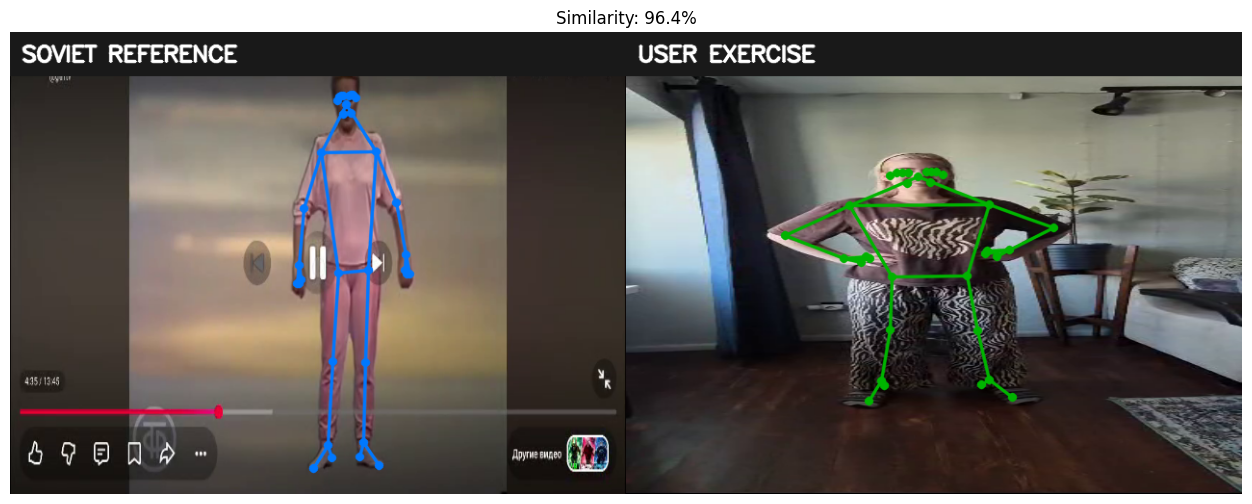

In [ ]:
# Номер пары сопоставленных кадров.
# Можно менять число, чтобы смотреть разные моменты упражнения.
alignment_id = min(
    10,
    n_frames - 1,
)

# Реальный номер кадра в эталонном видео.
reference_frame_id = int(
    reference_frame_ids[
        alignment_id
    ]
)

# Реальный номер кадра в пользовательском видео.
user_frame_id = int(
    user_frame_ids[
        alignment_id
    ]
)

# Берём реальные кадры из двух видео и приводим
# только изображение к одинаковому размеру для показа.
reference_frame = cv2.resize(
    reference.frames[
        reference_frame_id
    ],
    (
        DISPLAY_WIDTH,
        DISPLAY_HEIGHT,
    ),
)

user_frame = cv2.resize(
    user.frames[
        user_frame_id
    ],
    (
        DISPLAY_WIDTH,
        DISPLAY_HEIGHT,
    ),
)

# Метрики соответствующей пары кадров.
similarity = metrics.loc[
    alignment_id,
    "cosine_similarity",
]

similarity_percent = metrics.loc[
    alignment_id,
    "similarity_percent",
]

distance = metrics.loc[
    alignment_id,
    "weighted_distance",
]

confidence = metrics.loc[
    alignment_id,
    "confidence",
]

# Скелет эталона.
reference_visualization = draw_pose(
    reference_frame,
    reference_poses[
        alignment_id
    ],
    (255, 120, 0),
    "SOVIET REFERENCE",
)

# Скелет пользователя.
user_visualization = draw_pose(
    user_frame,
    user_poses[
        alignment_id
    ],
    metric_color(similarity),
    "USER EXERCISE",
)

# Два изображения рядом.
comparison = np.hstack(
    [
        reference_visualization,
        user_visualization,
    ]
)

# Заголовок показывает реальные кадры и метрики.
title = (
    f"Reference frame: {reference_frame_id} | "
    f"User frame: {user_frame_id} | "
    f"Similarity: {similarity_percent:.1f}% | "
    f"Distance: {distance:.4f} | "
    f"Confidence: {confidence:.2f}"
)

plt.figure(
    figsize=(18, 7),
)

plt.imshow(
    cv2.cvtColor(
        comparison,
        cv2.COLOR_BGR2RGB,
    )
)

plt.axis("off")

plt.title(
    title,
    fontsize=12,
)

plt.show()

## 9. Рекомендация коуча


In [13]:
mean_similarity = metrics["similarity_percent"].mean()
mean_distance = metrics["weighted_distance"].mean()
mean_confidence = metrics["confidence"].mean()
mean_cosine = metrics["cosine_similarity"].mean()

message = get_coach_message(
    mean_cosine,
    mean_distance,
    mean_confidence,
)

print(f"Среднее сходство: {mean_similarity:.2f}%")
print(f"Среднее взвешенное расстояние: {mean_distance:.4f}")
print(f"Средняя достоверность: {mean_confidence:.4f}")
print("\nРекомендация виртуального коуча:")
print(message)


Среднее сходство: 89.87%
Среднее взвешенное расстояние: 1.9212
Средняя достоверность: 0.9275

Рекомендация виртуального коуча:
Check arms and legs position


## 10. Графики


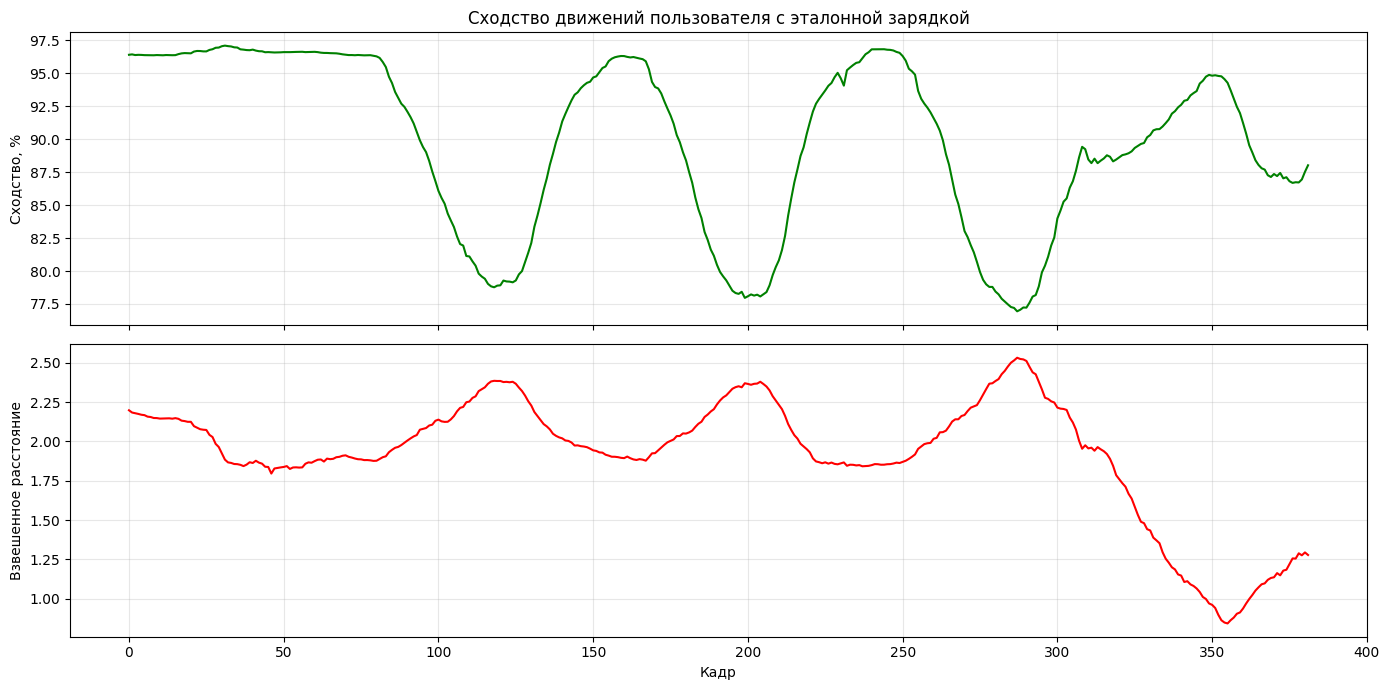

График сохранён: C:\Users\aleks\Documents\IDE\morning_exercise_coach\output\metrics_plot.png


In [14]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(metrics["frame"], metrics["similarity_percent"], color="green")
axes[0].set_title("Сходство движений пользователя с эталонной зарядкой")
axes[0].set_ylabel("Сходство, %")
axes[0].grid(alpha=0.3)

axes[1].plot(metrics["frame"], metrics["weighted_distance"], color="red")
axes[1].set_xlabel("Кадр")
axes[1].set_ylabel("Взвешенное расстояние")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=150)
plt.show()
print("График сохранён:", PLOT_PATH)


## 11. Просмотр итогового видео


In [15]:
if OUTPUT_VIDEO.exists():
    display(Video(str(OUTPUT_VIDEO), embed=True, width=900))
else:
    print("Итоговое видео ещё не создано.")
    print("Запустите в PowerShell: py -3.11 scripts/main.py")


Итоговое видео ещё не создано.
Запустите в PowerShell: py -3.11 scripts/main.py
